Projet Info 3 - Python scientifique - 20/12/2025

Pedro Luna et Enzo Endo

L'objectif de ce travail est d'utiliser les outils développés au cours des travaux pratiques pour réaliser un projet plus ample selon un scénario prédéfini. Nous avons retenu le thème de la modélisation de la propagation des virus/maladies.

Notre travail consiste à modéliser la propagation du virus Covid-19 en France à partir de données réelles  (Johns Hopkins University) sur les cas cumulés. La modélisation sera réalisée à l'aide du modèle SIR (Susceptible-Infecté-Retiré/Récupéré) discret en 3 variantes.

Nous utiliserons l'approche d'Allen (1994) pour modéliser l'épidémie dans le temps discret. Cette méthode remplace le calcul continu avec des équations différentielles par des intervalles discrets. Dans notre cas, nous considérons qu'elle est préférable, car sa mise en œuvre est plus intuitive et nous pouvons simuler les changements dans les groupes de manière séquentielle.

Trois variantes seront développées :

1. SIR classique - Modélisation de l'article d'Allen (1994)
2. SIRSD -  En tenant compte d'une possible réinfection et en différenciant les guéris des morts (au lieu de simplement « retirés »)
3. SIRSD - Taux d'infection qui changent avec le temps

Les résultats des modèles seront comparés et présentés avec l'évolution réelle des cas, en réalisant également des estimations et des approximations basées sur ce que nous savons de la maladie et sur des sources telles que l'Institut national de la statistique et des études économiques (INSEE, 2021).

1 : Importation des bibliothèques

Numpy : utilisé pour manipuler les tableaux où se trouvent les différents groupes, ainsi que certaines fonctions spécifiques.

Pandas : principalement utilisé pour manipuler et organiser les données que nous allons utiliser pour analyser la progression de la pandémie.

Matplotlib : utilisé pour visualiser les principales informations étudiées dans les données réelles et les modèles affinés. 

Seabornd : utilisé pour améliorer les tracés générés.

Scipy : utilisé pour trouver les meilleurs paramètres possibles afin d'optimiser le modèle.  



In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit

2 : Origine des données

Nous avons importé les séries chronologiques des cas confirmés cumulés à partir du référentiel de l'université Johns Hopkins, une base de données mondiale utilisée pour suivre la pandémie. Les données sont structurées chronologiquement par pays, fournissant ainsi ce dont nous avons besoin pour ajuster les courbes et calibrer les paramètres du modèle.

In [20]:
# data (Johns Hopkins University)
# Link repository: https://github.com/CSSEGISandData/COVID-19

#raw data:
# URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
# df = pd.read_csv(URL)

df = pd.read_csv('time_series_covid19_confirmed_global.csv')


3 : Préparation des données nécessaires

Comme les données pour la France sont réparties par territoire, nous avons additionné toutes les régions pour obtenir une valeur unique représentant l'ensemble du pays. Ainsi, nous avons utilisé uniquement le nom du pays et le nombre total de cas cumulés par jour, en ignorant les divisions régionales et les coordonnées géographiques.

De plus, nous avons obtenu le nombre total de jours et avons estimé la durée de l'infection à 10 jours. Nous ne disposons pas directement des cas quotidiens, nous avons donc calculé la différence entre « aujourd'hui et hier » et additionné les 10 derniers jours pour (obtenir le nombre total de personnes infectées à un instant donné)

In [21]:
# filtrer France - somme des cas par région et ajuster le format

france_filtered = df[df['Country/Region'] == 'France']
time_series_only = france_filtered.iloc[:, 4:] #On isole la série temporelle en supprimant les données géographiques
france_data = time_series_only.sum(axis=0)
france_data.index = pd.to_datetime(france_data.index, errors='coerce') #dates réelles pour l'analyse temporelle

y_real_acc = france_data.values.astype(float) # cas cumulés totaux (C)
x_days = np.arange(len(y_real_acc)) # nombre total de jours

# nouveaux cas (aujourd'hui - hier)
y_daily = np.diff(y_real_acc, prepend=0)

# estimation des cas actifs - Somme des nouveaux cas des 10 derniers jours
active_series = pd.Series(y_daily).rolling(window=10).sum()
y_real_active = active_series.fillna(0).values #initialisation à zéro des premiers jours

N = 67500000 # population estimée de la France

C:\Users\pedro\AppData\Local\Temp\ipykernel_17824\2072580214.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index, errors='coerce') #dates réelles pour l'analyse temporelle


4 : Vérification des données

Cette cellule sert uniquement à vérifier si les données traitées sont bien celles souhaitées. Nous pouvons les comparer avec le fichier CSV original.

In [22]:
print(f"Données : {len(x_days)} jours de pandémie.")
print(f"Total cumulé final : {y_real_acc[-1]:,.0f}")

print(y_real_acc[20:30])    # Cas cumulés
print(y_daily[30:40])       # Nouveaux cas par jour
print(y_real_active[40:50]) # Estimation des cas actifs

Données : 1143 jours de pandémie.
Total cumulé final : 39,866,718
[11. 11. 11. 11. 12. 12. 12. 12. 12. 12.]
[ 0.  0.  0.  0.  2.  4. 20. 19. 43. 30.]
[ 179.  200.  276.  414.  602.  930. 1087. 1354. 1683. 2163.]


5 : Modélisation SIR

Considérant un intervalle de temps $\Delta t = 1$ jour, les équations qui montrent la dynamique du système sont :

$$\begin{aligned}
S_{t+1} &= S_t - \frac{\beta}{N} S_t I_t \\
I_{t+1} &= I_t + \frac{\beta}{N} S_t I_t - \gamma I_t \\
R_{t+1} &= R_t + \gamma I_t
\end{aligned}$$

**Variables d'État :**

* **$S_t$** : Nombre d'individus susceptibles.
* **$I_t$** : Nombre d'individus infectés.
* **$R_t$** : Nombre d'individus retirés (immunisés ou décédés).
* **$N$** : Population totale.

**Paramètres du Modèle :**

* **$\beta$** : Coefficient de transmission (taux de contact effectif quotidien).
* **$\gamma$** : Taux de récupération quotidien (où $1/\gamma$ représente la période moyenne d'infection).

In [23]:
def sir_discrete(t, beta, gamma, return_full=False):
    
    #crée des tableaux à remplir avec la mise à jour quotidienne du système
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 100) #garantit que la pandémie commencera avec au moins 100 infectés
    S[0] = N - I[0] 
    
    for i in range(len(t) - 1):
        
        #modélisation présentée
        new_inf = (beta * S[i] * I[i]) / N #nouveaux infectés du jour
        new_rec = gamma * I[i] #nouveaux récupérés du jour
        
        #mise à jour des variables
        #max (0,_) garantit que l'on n'atteigne pas de valeurs négatives
        S[i+1] = max(0, S[i] - new_inf) #prochain jour susceptibles = susceptibles actuels - infectés actuels
        I[i+1] = max(0, I[i] + new_inf - new_rec) #prochain jour infectés = infectés actuels - retirés actuels
        R[i+1] = R[i] + new_rec
    
    #deux retours possibles : un pour l'optimisation et un autre pour le plot/analyse
    if return_full:
        return S, I, R, (I + R) #plot/analyse
    return I + R #optimisation (somme des tableaux de tous ceux qui ont été infectés pendant ce temps)

6 : Modélisation SIRS-D

Considérant l'introduction de la réinfection et de la létalité dans le système, les équations sont :

$$\begin{aligned}
S_{t+1} &= S_t - \frac{\beta}{N} S_t I_t + \xi R_t \\
I_{t+1} &= I_t + \frac{\beta}{N} S_t I_t - \gamma I_t - \mu I_t \\
R_{t+1} &= R_t + \gamma I_t - \xi R_t \\
D_{t+1} &= D_t + \mu I_t
\end{aligned}$$

**Variables d'État:**

* **$S_t$** : Nombre d'individus susceptibles.
* **$I_t$** : Nombre d'individus infectés.
* **$R_t$** : Nombre d'individus récupérés (immunisés temporairement).
* **$D_t$** : Nombre cumulé de décès.
* **$N$** : Population totale.

**Nouveaux Paramètres du Modèle :**

* **$\xi$** : Taux de perte d'immunité (fraction de récupérés qui redeviennent susceptibles par jour).
* **$\mu$** : Taux de létalité quotidien (probabilité de décès pour un infecté).

In [24]:
def sirsd_discrete(t, beta, gamma, xi, mu, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    D = np.zeros(len(t)) #décès quotidiens
    C = np.zeros(len(t)) #infectés quotidiens
    
    I[0] = max(y_real_acc[0], 100)
    C[0] = max(y_real_acc[0], 100)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):

        #modélisation présentée
        new_inf = (beta * S[i] * I[i]) / N #identique au SIR
        new_rec = gamma * I[i] #identique au SIR
        new_death = mu * I[i] #décès quotidiens
        new_susc = xi * R[i]  #perte d'immunité
        
        #mise à jour quotidienne des groupes
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec - new_death) 
        R[i+1] = max(0, R[i] + new_rec - new_susc) # récupérés du jour + nouveaux récupérés - nouveaux susceptibles
        D[i+1] = D[i] + new_death #uniquement les décès par jour
        C[i+1] = C[i] + new_inf #comptage total des cas
        
    if return_full:
        return S, I, R, D, C 
    return C

7 : Modélisation SIRS-D Dynamique 

Dans cette approche, la structure est la même que celle du modèle SIRS-D, mais le coefficient de transmission ($\beta_t$) varie au fil du temps.

La période analysée est divisée en intervalles temporels, définis par des points de coupure ($x_{nodes}$). À l'intérieur de chaque intervalle, la valeur de $\beta$ reste constante, s'ajustant uniquement lors de la transition entre les phases :

$$
\beta_t = 
\begin{cases} 
\beta_1 & \text{si } t_{début} \le t < x_1 \\
\beta_2 & \text{si } x_1 \le t < x_2 \\
\vdots & \vdots \\
\beta_k & \text{si } x_{k-1} \le t \le t_{final}
\end{cases}
$$

**Modification des Paramètres :**

* **$\beta_t$** (Beta Variable) : Prend des valeurs différentes pour chaque phase, en tenant compte des changements de comportement social, des politiques publiques et des différents variants de la maladie.
* **$x_{nodes}$** : Points temporels pour les changements de phase.

**Mise en œuvre :** Pour ce cas, nous avons défini le nombre d'intervalles à **4**. Ce choix a été basé sur l'identification de quatre grandes vagues de contagion au cours de la période, selon les références utilisées (INSEE, 2021).

In [25]:
n_intervals = 4  
x_nodes = np.linspace(0, len(x_days), n_intervals + 1)

def sirs_dynamic_discrete(t, gamma, xi, mu, *betas_array, return_full=False):
    
    #mêmes paramètres 
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    D = np.zeros(len(t)) 
    C = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 100)
    C[0] = max(y_real_acc[0], 100)
    S[0] = N - I[0]
    
    
    for i in range(len(t) - 1):
        
        idx = np.searchsorted(x_nodes, i, side='right') - 1 #identifie l'indice de l'intervalle où se trouve le jour 'i'
        idx = max(0, min(idx, len(betas_array) - 1)) # garantit que l'indice est dans les limites du tableau
        
        # Sélectionne le Beta correct pour ce jour-là
        beta_t = betas_array[idx]
       
        # même modélisation que le sirsd
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_death = mu * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec - new_death)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        D[i+1] = D[i] + new_death
        C[i+1] = C[i] + new_inf
        
    if return_full: 
        return S, I, R, D, C 
    return C

Remarque sur la création de fonctions :  

Étant donné que la modélisation de chacun des systèmes est incrémentielle, il serait possible de créer une seule fonction avec plusieurs conditions pour chacun des cas d'étude. Cependant, cette approche n'a pas été retenue car elle rendrait la lecture du code plus difficile et serait plus confuse au moment d'utiliser les fonctions pour l'optimisation et le traçage. 

8 : Contraintes

Comme il s'agit d'un modèle d'une maladie connue, certaines contraintes doivent être imposées afin que le système ne trouve pas de paramètres qui ne reflètent pas la réalité (comme un temps d'infection trop court ou une mortalité trop élevée). Nous avons défini des points de départ appropriés pour accélérer la convergence.


In [ ]:
#Configuration des limites 

min_days_rec = 7    
max_days_rec = 21  
min_days_imu   = 62  
max_days_imu   = 365 
min_prob_death_day   = 0.00001 
max_prob_death_day   = 0.001   
max_beta = 5.0   

gamma_min = 1 / max_days_rec #récupération
gamma_max = 1 / min_days_rec

xi_min = 1 / max_days_imu #perte d'immunité
xi_max = 1 / min_days_imu

print(f"Limites converties :") #limites converties pour les paramètres
print(f"Gamma : {gamma_min:.4f} à {gamma_max:.4f}")
print(f"Xi :    {xi_min:.5f} à {xi_max:.5f}")



Limites converties :
 > Gamma : 0.0476 à 0.1429
 > Xi :    0.00274 à 0.01613


9 : Optimisation

Nous utilisons des algorithmes de minimisation pour ajuster les courbes du modèle aux données réelles, en cherchant à réduire l'erreur entre la simulation et l'historique.

**Paramètres**
* **SIR Classique :** Ajuste $\beta$ et $\gamma$.
* **SIRS-D (Statique) :** Ajuste $\beta, \gamma, \xi$ et $\mu$.
* **SIRS-D (Dynamique) :** Ajuste le vecteur de **Betas ($\beta_{1} \dots \beta_k$)**, tout en maintenant $\gamma, \xi, \mu$ constants.

L'algorithme cherche à trouver la valeur optimale des paramètres qui minimise l'erreur.

In [ ]:
# SIR

# limites imposées SIR
bounds_sir = ([0.0, gamma_min], [max_beta, gamma_max])

popt_sir, _ = curve_fit(sir_discrete, x_days, y_real_acc, 
                            p0=[0.1, 0.1], 
                            bounds=bounds_sir)

In [ ]:
# SIRSD

# valeurs initiales
p0_sirsd = [0.1, 0.1, 0.005, 0.0001] # Paramètres : Beta, Gamma, Xi, Mu

# limites imposées SIRSD
bounds_sirsd = ([0.0, gamma_min, xi_min, min_prob_death_day], 
                [max_beta, gamma_max, xi_max, max_prob_death_day])

popt_sirds, _ = curve_fit(sirsd_discrete, x_days, y_real_acc, 
                    p0=p0_sirsd, 
                    bounds=bounds_sirsd)

In [ ]:
# SIRSD Dynamique

# valeurs initiales
init_dyn = [0.08, 0.005, 0.0005] + [0.15] * n_intervals # Paramètres : Gamma, Xi, Mu, [Beta1, Beta2, ... BetaN]

# limites imposées
lower_fixed = [gamma_min, xi_min, min_prob_death_day] # partie fixe : [Gamma, Xi, Mu]
upper_fixed = [gamma_max, xi_max, max_prob_death_day]
lower_betas = [0.0] * n_intervals # partie Variable : [Beta, Beta, ...]
upper_betas = [max_beta] * n_intervals
low_dyn = lower_fixed + lower_betas # concaténation
up_dyn  = upper_fixed + upper_betas

popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real_acc, 
                        p0=init_dyn, 
                        bounds=(low_dyn, up_dyn), 
                        maxfev=30000)


print(f"Optimisation terminée")

Optimisation terminée


10 : Simulation avec Paramètres Optimisés

Avec les meilleurs paramètres trouvés par l'algorithme, nous exécutons la simulation définitive pour générer les graphiques et rapports.

* L'opérateur * extrait les valeurs de la liste optimisée et les insère dans la fonction comme arguments ($\beta, \gamma, \dots$).  
* return_full=True configure le modèle pour retourner les séries temporelles complètes de tous les groupes, permettant le traçage et la comparaison avec les données réelles.

In [134]:
# nous obtenons l'évolution des populations pour chacun des modèles avec les paramètres optimisés

S_sir, I_sir, R_sir, C_sir = sir_discrete(x_days, *popt_sir, return_full=True)

S_sirsd, I_sirsd, R_sirsd, D_sirsd, C_sirsd = sirsd_discrete(x_days, *popt_sirds, return_full=True)

S_dyn, I_dyn, R_dyn, D_dyn, C_dyn = sirs_dynamic_discrete(x_days, *popt_dyn, return_full=True)

11 : Rapport des résultats

Avant les graphiques, un rapport est généré avec les principaux paramètres et informations trouvés après l'optimisation. Il sert à la comparaison et à l'évaluation du modèle. Nous pouvons ainsi vérifier si les résultats obtenus sont réalistes.

En plus des paramètres les plus directs présentés, nous avons :

**R0** :

C'est la moyenne des nouveaux cas générés par un seul individu infecté dans une population susceptible.

**Létalité** :

Elle représente le pourcentage d'individus infectés dont l'issue est le décès.

In [34]:
print(f"{'Comparaison des modèles':^80}")


# [1] MODÈLE SIR

beta, gamma = popt_sir
recovery_days_sir = 1 / gamma # calcul du temps moyen d'infection

print(f"\n[1] MODÈLE SIR (Basique)")
print(f"    ├─ Beta : {beta:.4f}  |  Gamma : {gamma:.4f} (~{recovery_days_sir:.1f} jours)")
print(f"    └─ R0 :   {beta/gamma:.4f}   (Immunité Permanente)")

# [2] MODÈLE SIRS-D (STATIQUE - MOYENNE GÉNÉRALE)

beta, gamma, xi, mu = popt_sirds

recovery_days = 1 / gamma 
immunity_days = 1 / xi 
lethality_pct = (mu / (gamma + mu)) * 100
r0 = beta / (gamma + mu)

print(f"\n[2] MODÈLE SIRS-D (Statique)")
print(f"    ├─ Beta : {beta:.4f}  |  Gamma : {gamma:.4f} (~{recovery_days:.1f} jours) |  Mu : {mu:.5f}")
print(f"    ├─ Xi :   {xi:.5f} ({immunity_days:.1f} jours d'immunité)")
print(f"    └─ R0 :   {r0:.4f}  |  Létalité : {lethality_pct:.2f}%")


# [3] SIRSD Dynamique

# Sépare les paramètres : Gamma, Xi, Mu et la liste de Betas
gamma, xi, mu, *betas = popt_dyn 

# Calculs fixes
immunity_days = 1 / xi 
lethality_pct = (mu / (gamma + mu)) * 100

print(f"\n[3] MODÈLE DYNAMIQUE (Par Phases)")
print(f"    [PARAMÈTRES BIOLOGIQUES FIXES]")
print(f"    ├─ Gamma : {gamma:.4f} (Récupération ~{1/gamma:.1f} jours)")
print(f"    ├─ Mu :    {mu:.5f}")
print(f"    ├─ Xi :    {xi:.5f} ({immunity_days:.1f} jours d'immunité)")
print(f"    └─ Létalité du Modèle : {lethality_pct:.2f}%")

print(f"\n    [PHASES DE TRANSMISSION (BETA VARIABLE)]")

# boucle qui montre les valeurs de beta selon l'intervalle de temps
for i, b in enumerate(betas):

    if i < len(x_nodes) - 1:
        # le début est le nœud actuel et la fin est le nœud suivant
        start_day = int(x_nodes[i])
        end_day   = int(x_nodes[i+1])
        
        r0 = b / (gamma + mu)
        
        print(f"    ├─ Phase {i+1:02d} (Jour {start_day:4d} à {end_day:4d}) : "
              f"Beta = {b:.4f}  ->  R0 ≈ {r0:.2f}")

                            Comparaison des modèles                             

[1] MODÈLE SIR (Basique)
    ├─ Beta : 0.0642  |  Gamma : 0.0476 (~21.0 jours)
    └─ R0 :   1.3479   (Immunité Permanente)

[2] MODÈLE SIRS-D (Statique)
    ├─ Beta : 0.0730  |  Gamma : 0.0563 (~17.8 jours) |  Mu : 0.00100
    ├─ Xi :   0.00332 (301.6 jours d'immunité)
    └─ R0 :   1.2738  |  Létalité : 1.74%

[3] MODÈLE DYNAMIQUE (Par Phases)
    [PARAMÈTRES BIOLOGIQUES FIXES]
    ├─ Gamma : 0.1319 (Récupération ~7.6 jours)
    ├─ Mu :    0.00100
    ├─ Xi :    0.00274 (365.0 jours d'immunité)
    └─ Létalité du Modèle : 0.75%

    [PHASES DE TRANSMISSION (BETA VARIABLE)]
    ├─ Phase 01 (Jour    0 à  285) : Beta = 0.1611  ->  R0 ≈ 1.21
    ├─ Phase 02 (Jour  285 à  571) : Beta = 0.1324  ->  R0 ≈ 1.00
    ├─ Phase 03 (Jour  571 à  857) : Beta = 0.1681  ->  R0 ≈ 1.26
    ├─ Phase 04 (Jour  857 à 1143) : Beta = 0.1828  ->  R0 ≈ 1.38


12: Graphiques et Résultats

Maintenant les principaux résultats finaux présentés sous forme de graphiques. Tous les graphiques sont auto-explicatifs.

Le plus grand défi ici a été de développer des graphiques faciles à visualiser. Cela a été difficile principalement en raison du chevauchement des modèles et de la grande différence entre les valeurs des groupes (beaucoup moins de personnes infectées et décédées que de personnes susceptibles). Nous essayons de conserver le même style esthétique pour tous les graphiques

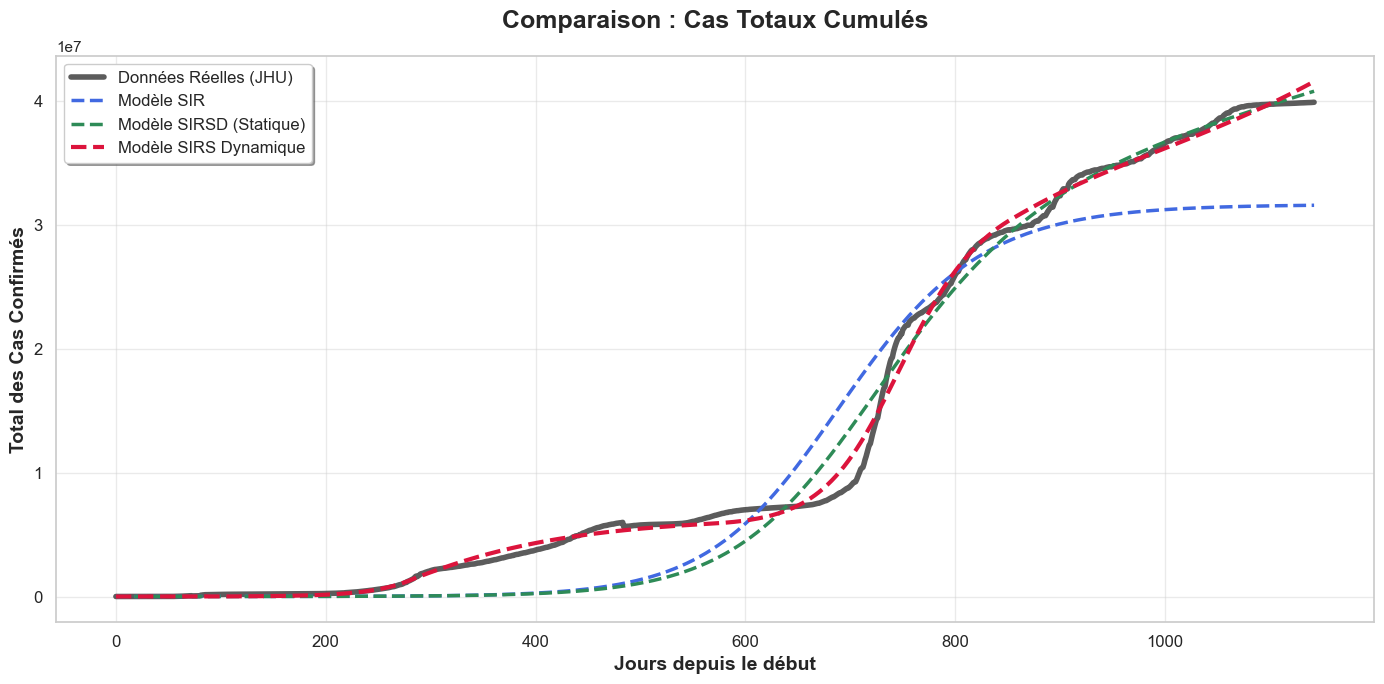

In [140]:
def plot_comparison_total_cases(x_days, y_real_acc, C_sir, C_sirsd, C_dyn):

    # seaborn
    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(14, 7))
    plt.title("Comparaison : Cas Totaux Cumulés", fontsize=18, fontweight='bold', pad=20)

    # données réelles
    plt.plot(x_days, y_real_acc, color='#333333', label='Données Réelles (JHU)', 
             linewidth=4, zorder=1, alpha=0.8)

    # SIR
    plt.plot(x_days, C_sir, label='Modèle SIR', linestyle='--', 
             color='royalblue', linewidth=2.5, zorder=2)

    # SIRSD
    plt.plot(x_days, C_sirsd, label='Modèle SIRSD (Statique)', linestyle='--', 
             color='seagreen', linewidth=2.5, zorder=3)

    # SIRSD Dynamique
    plt.plot(x_days, C_dyn, label='Modèle SIRS Dynamique', linestyle='--', 
             color='crimson', linewidth=3, zorder=4)

    plt.ylabel("Total des Cas Confirmés", fontsize=14, fontweight='bold')
    plt.xlabel("Jours depuis le début", fontsize=14, fontweight='bold')

    plt.legend(fontsize=12, frameon=True, shadow=True, loc='upper left')
    plt.grid(True, which='major', linestyle='-', alpha=0.4)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    plt.tight_layout()
    plt.show()

plot_comparison_total_cases(x_days, y_real_acc, C_sir, C_sirsd, C_dyn)

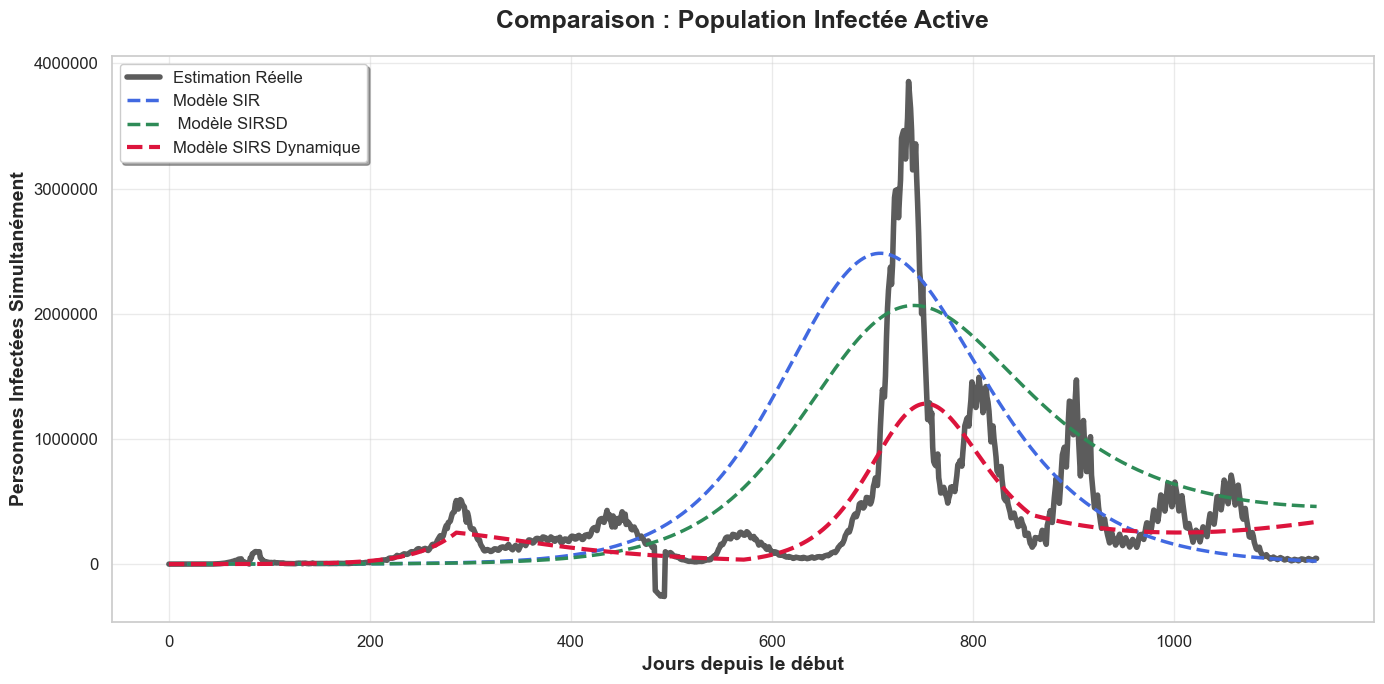

In [ ]:
def plot_comparison_active_infections(x_days, y_real_active, I_sir, I_sirsd, I_dyn):

    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(14, 7))
    plt.title("Comparaison : Population Infectée Active", fontsize=18, fontweight='bold', pad=20)

    # estimation réelle 
    plt.plot(x_days, y_real_active, color='#333333', label='Estimation Réelle', 
             linewidth=4, zorder=1, alpha=0.8)

    # SIR 
    plt.plot(x_days, I_sir, label='Modèle SIR', linestyle='--', 
             color='royalblue', linewidth=2.5, zorder=2)

    # SIRSD 
    plt.plot(x_days, I_sirsd, label=' Modèle SIRSD', linestyle='--', 
             color='seagreen', linewidth=2.5, zorder=3)

    # SIRSD dynamic
    plt.plot(x_days, I_dyn, label='Modèle SIRS Dynamique', linestyle='--', 
             color='crimson', linewidth=3, zorder=4)

    plt.ylabel("Personnes Infectées Simultanément", fontsize=14, fontweight='bold')
    plt.xlabel("Jours depuis le début", fontsize=14, fontweight='bold')

    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.grid(True, which='major', linestyle='-', alpha=0.4)
    plt.ticklabel_format(style='plain', axis='y') 
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    plt.tight_layout()
    plt.show()

plot_comparison_active_infections(x_days, y_real_active, I_sir, I_sirsd, I_dyn)

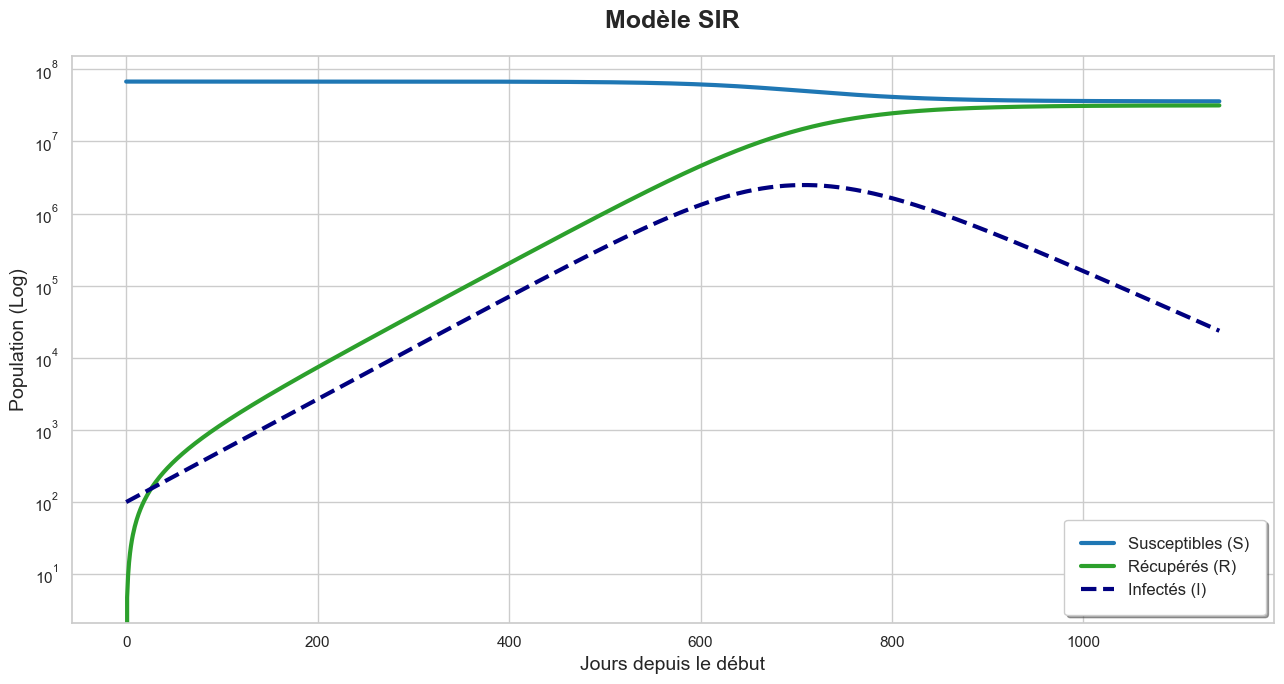

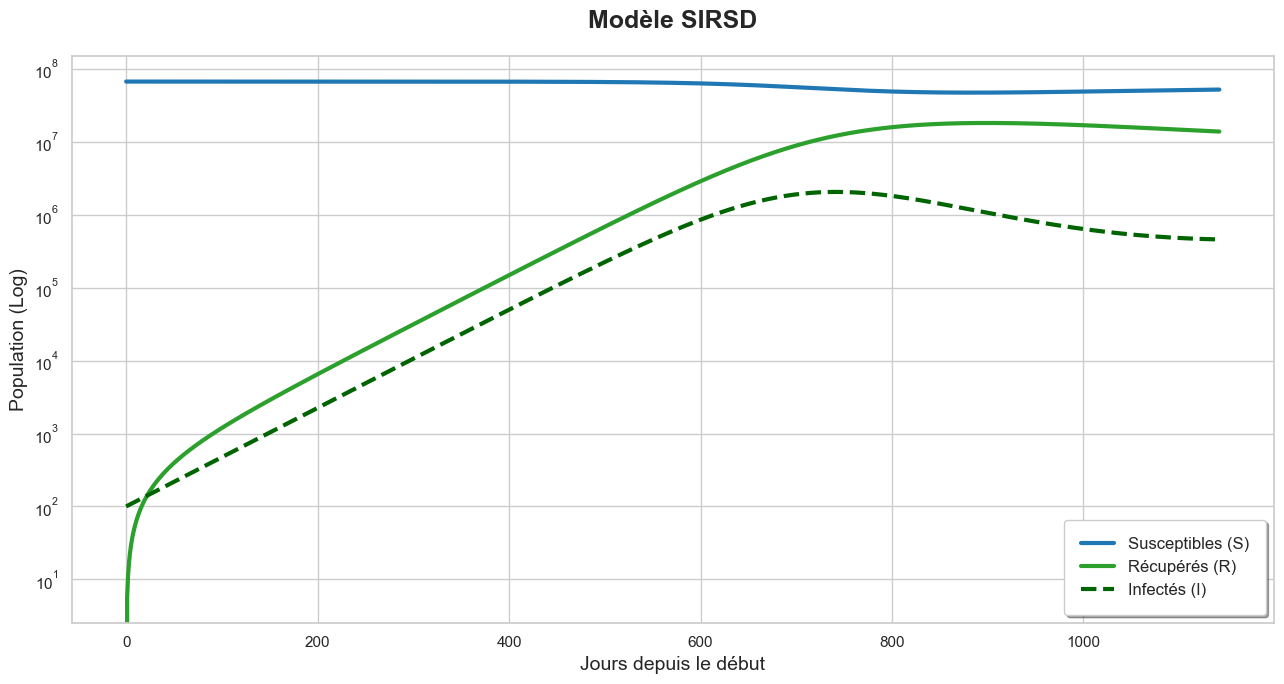

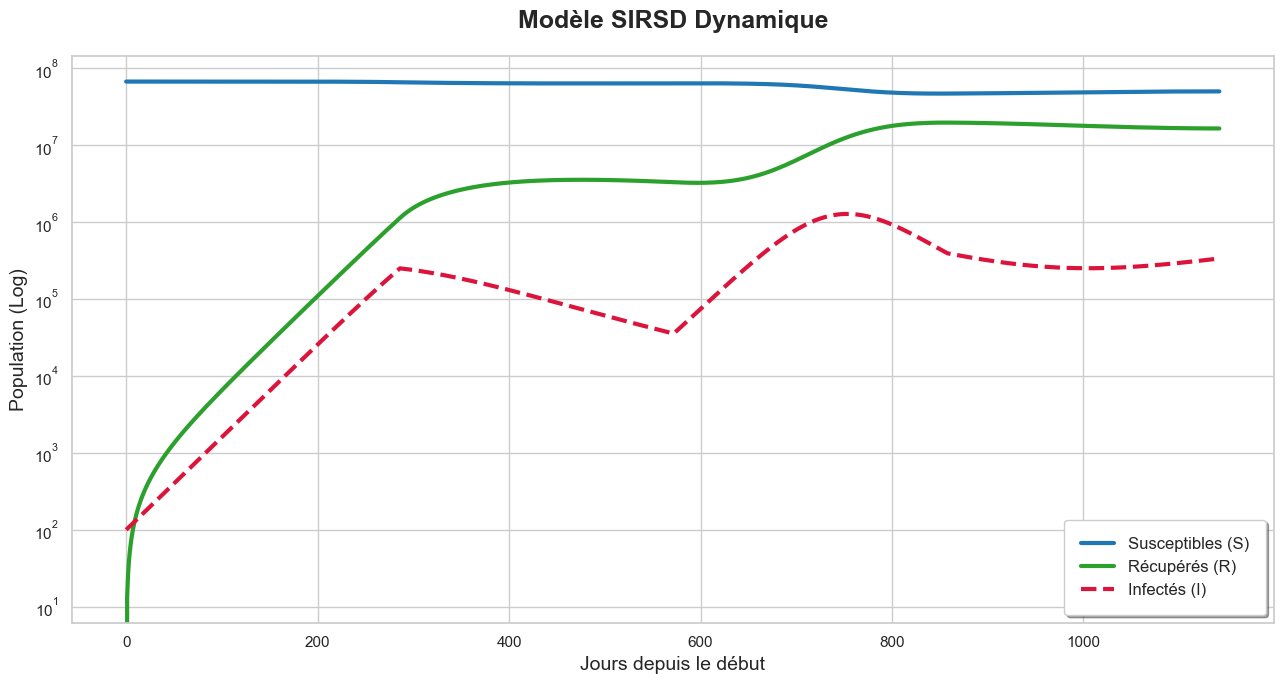

In [152]:
def plot_dynamics_log(model_title, S, I, R, color_i):

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(13, 7))
    
    plt.title(model_title, fontsize=18, fontweight='bold', pad=20)
    
    # Curves
    plt.plot(x_days, S, label='Susceptibles (S)', color='tab:blue', linewidth=3, zorder=2)
    plt.plot(x_days, R, label='Récupérés (R)', color='tab:green', linewidth=3, zorder=2)
    plt.plot(x_days, I, label='Infectés (I)', color=color_i, linewidth=3, linestyle='--', zorder=3)
    
    # Scale - nous utilisons un log pour mieux visualiser toutes les courbes
    plt.yscale('log')

    plt.xlabel("Jours depuis le début", fontsize=14)
    plt.ylabel("Population (Log)", fontsize=14)
    plt.legend(loc='lower right', fontsize=12, frameon=True, shadow=True, borderpad=1)
    plt.tight_layout()
    plt.show()

plot_dynamics_log("Modèle SIR", S_sir, I_sir, R_sir, 'navy')
plot_dynamics_log("Modèle SIRSD", S_sirsd, I_sirsd, R_sirsd, 'darkgreen')
plot_dynamics_log("Modèle SIRSD Dynamique", S_dyn, I_dyn, R_dyn, 'crimson')

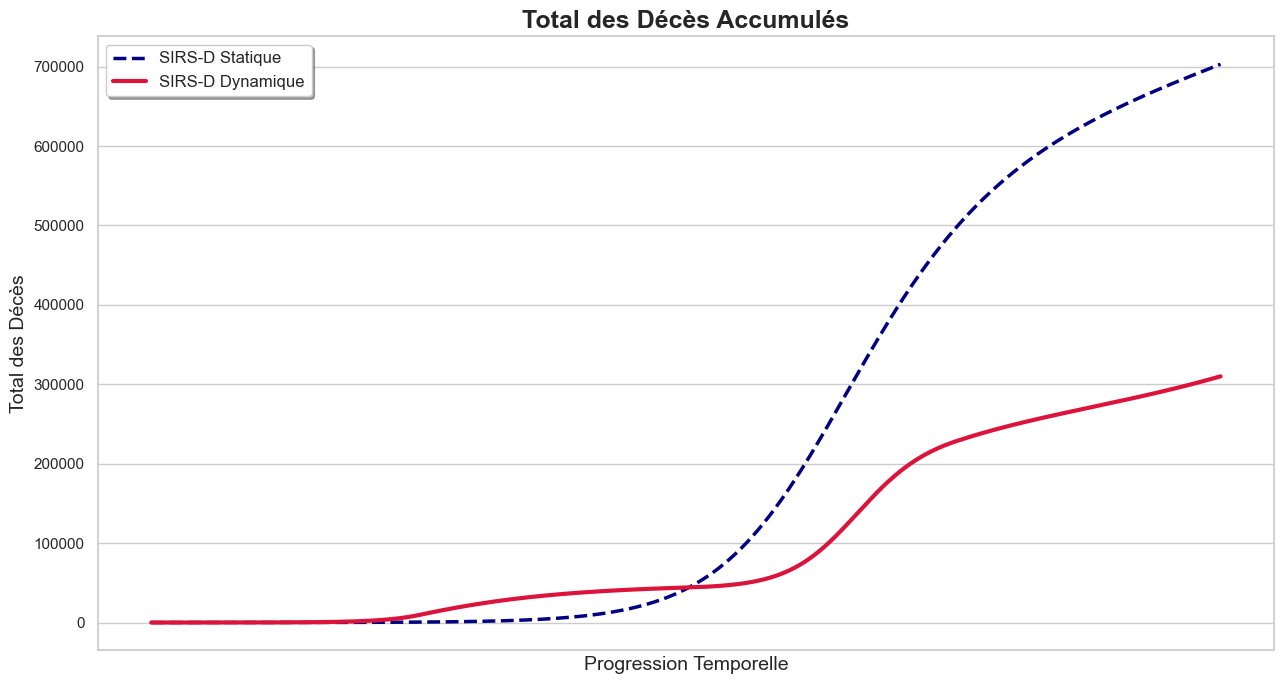

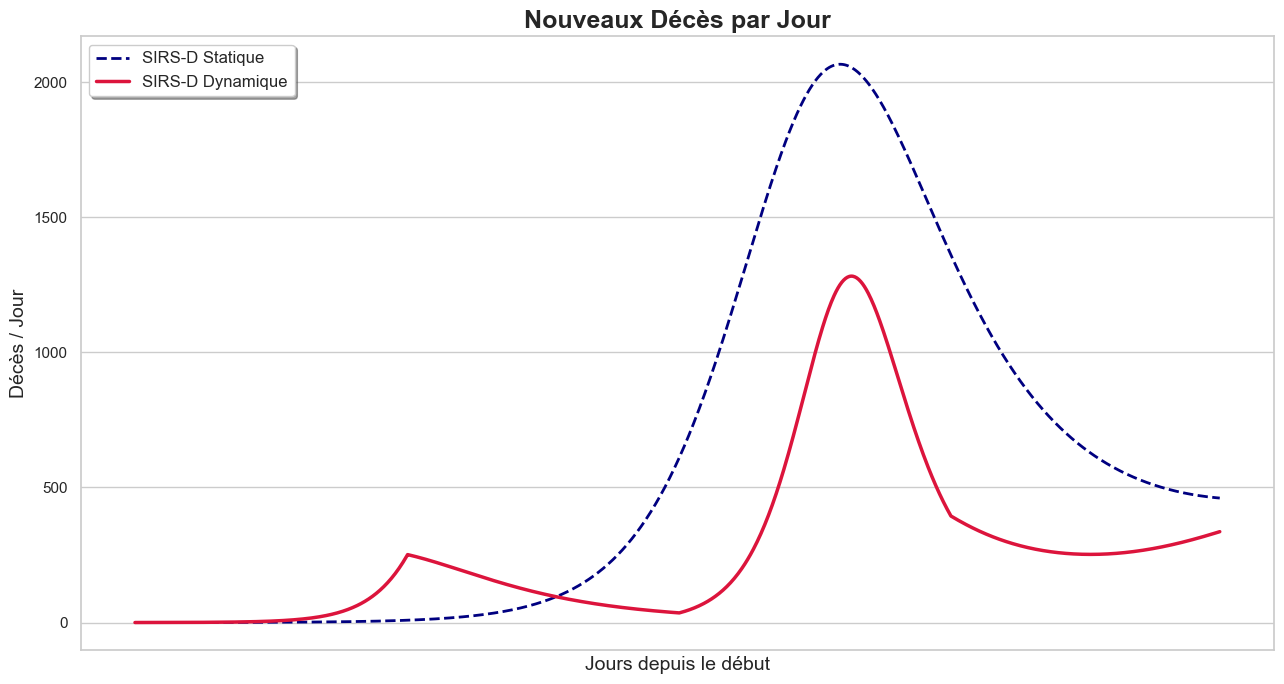

In [ ]:
def plot_death_comparison(days, total_deaths_static, total_deaths_dynamic):

    sns.set_theme(style="whitegrid")
    
    # data calc
    daily_static = np.diff(total_deaths_static, prepend=total_deaths_static[0])
    daily_dynamic = np.diff(total_deaths_dynamic, prepend=total_deaths_dynamic[0])
    
    #décès cumulés
    plt.figure(figsize=(13, 7))
    plt.title("Total des Décès Accumulés", fontsize=18, fontweight='bold')
    plt.plot(days, total_deaths_static, label='SIRSD', color='navy', linestyle='--', linewidth=2.5)
    plt.plot(days, total_deaths_dynamic, label='SIRSD Dynamique', color='crimson', linewidth=3)
    
     
    plt.gca().set_xticks([])
    plt.xlabel("Progression Temporelle", fontsize=14)
    plt.ylabel("Total des Décès", fontsize=14)
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()

    # décès quotidiens
    plt.figure(figsize=(13, 7))
    plt.title("Nouveaux Décès par Jour", fontsize=18, fontweight='bold')
    plt.plot(days, daily_static, label='SIRSD', color='navy', linestyle='--', linewidth=2)
    plt.plot(days, daily_dynamic, label='SIRSD Dynamique', color='crimson', linewidth=2.5)
    
    
    plt.gca().set_xticks([])
    plt.xlabel("Jours depuis le début", fontsize=14)
    plt.ylabel("Décès / Jour", fontsize=14)
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()


plot_death_comparison(x_days, D_sirsd, D_dyn)

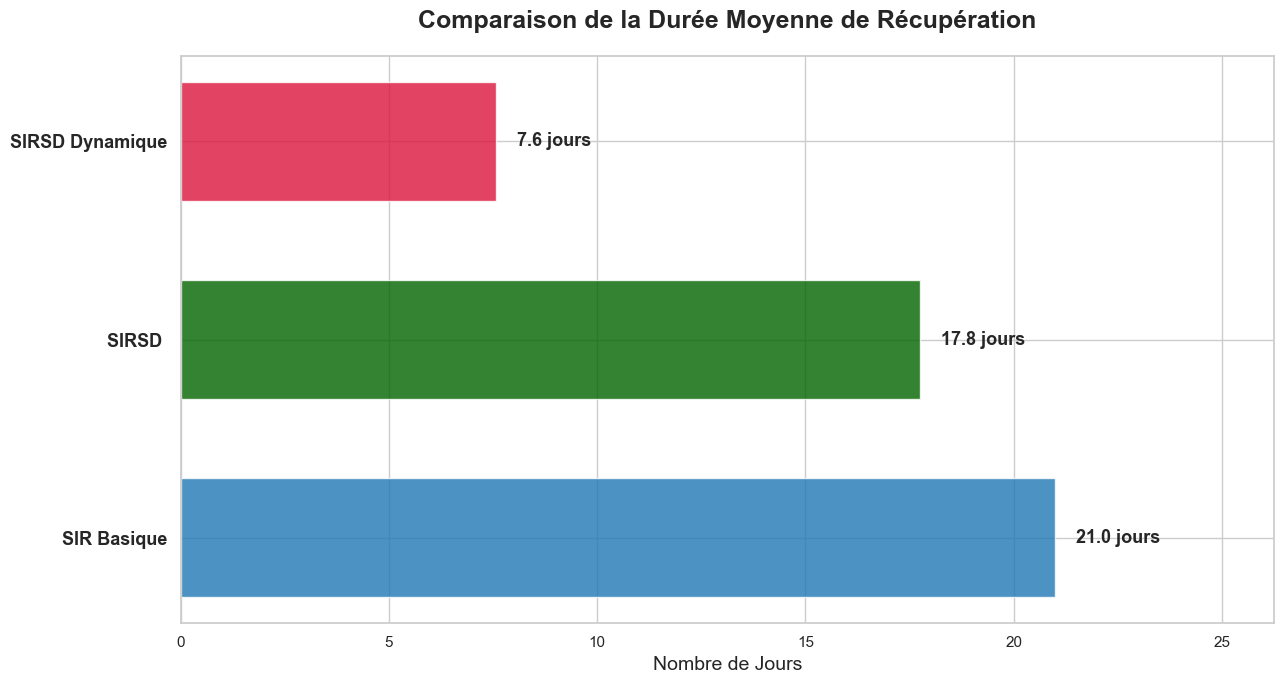

In [ ]:
def plot_recovery_comparison(popt_sir, popt_sirds, popt_dyn):

    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(13, 7))

    # Calcul des jours de récupération à partir du gamma

    val_sir = 1 / popt_sir[1] 
    val_sirsd = 1 / popt_sirds[1] 
    val_dyn = 1 / popt_dyn[0] 

    # barres
    ax.barh('SIR Basique', val_sir, color='tab:blue', alpha=0.8, height=0.6)
    ax.barh('SIRSD ', val_sirsd, color='darkgreen', alpha=0.8, height=0.6)
    ax.barh('SIRSD Dynamique', val_dyn, color='crimson', alpha=0.8, height=0.6)

    # texte
    ax.text(val_sir + 0.5, 0, f"{val_sir:.1f} jours", va='center', fontweight='bold', fontsize=13)
    ax.text(val_sirsd + 0.5, 1, f"{val_sirsd:.1f} jours", va='center', fontweight='bold', fontsize=13)
    ax.text(val_dyn + 0.5, 2, f"{val_dyn:.1f} jours", va='center', fontweight='bold', fontsize=13)

    # axes et titres
    ax.set_xlim(0, max(val_sir, val_sirsd, val_dyn) * 1.25)
    ax.set_title("Comparaison de la Durée Moyenne de Récupération", fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel("Nombre de Jours", fontsize=14)

    plt.yticks(fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


plot_recovery_comparison(popt_sir, popt_sirds, popt_dyn)

13 : Brève analyse

L'analyse de ce travail montre comment les mathématiques évoluent pour suivre une pandémie réelle. Nous commençons par le Modèle SIR Basique, une vision théorique où l'immunité est éternelle et où seuls ceux qui ont survécu à l'infection (décédés et guéris dans le même groupe) sont pris en compte. Il aide à comprendre les bases, mais il est très simple et n'a pas réussi à expliquer les nouvelles vagues de cas, car le virus cesse de circuler dès qu'il atteint un équilibre théorique attendu.

En passant au modèle SIRSD, le projet s'améliore en tenant compte du fait que l'immunité prend fin et qu'il y a des décès. Le modèle considère que le virus est toujours présent, mais il reste limité car il utilise des chiffres fixes pour une réalité en constante évolution.

Avec le Modèle Dynamique, qui s'est mieux adapté aux données de la pandémie en France. L'essentiel était de rendre le paramètre de transmission variable, permettant aux équations de montrer l'impact de l'isolement social et des nouveaux variants. Dans les graphiques, les différences sont plus évidentes. Le modèle dynamique se rapproche de la ligne réelle des données cumulées, tandis que les modèles statiques s'en écartent avec le temps.

Dans la courbe des personnes activement infectées, le modèle dynamique a dessiné les différentes vagues de contagion, contrairement au pic unique des modèles simples. Enfin, la réduction du temps de guérison à 7,6 jours dans le modèle dynamique montre que le virus circule beaucoup plus rapidement dans ce modèle que dans la théorie initiale. 

14 : Références :

Références bibliographiques:

1. **ALLEN, Linda J. S.** « Some Discrete-Time SI, SIR, and SIS Epidemic Models ». ***Mathematical Biosciences***, vol. 124, n° 1, p. 83-105, 1994.

2. **COSTEMALLE, V., GAINI, M., HAZO, J.-B. et NAOURI, D.** « En quatre vagues, l'épidémie de Covid-19 a causé 116 000 décès et lourdement affecté le système de soins ». In : ***France, portrait social***. Paris : Institut national de la statistique et des études économiques (Insee), 2021. Disponible sur : <https://www.insee.fr/fr/statistiques/5432509?sommaire=5435421>.